# Exploración de datos: ¿qué determina el precio de una propiedad?

Un portal inmobiliario nos compartió sus registros de venta. El objetivo es entender qué factores explican el precio de una propiedad, respondiendo cada pregunta de la consigna con un gráfico que la respalde.

**Estructura del trabajo**

0. Preparación del entorno
1. Descripción de los datos
2. Exploración inicial de las variables numéricas
3. Tamaño de un ambiente y una anomalía en la distribución
4. Pileta y precio
5. Casas vs. departamentos
6. Superficie y precio
7. Antigüedad y precio
8. Ubicación y precio
9. Fecha de venta y precio
10. Investigación de la anomalía: de dónde sale
11. Conclusiones

> **Criterio general:** antes de responder cada pregunta, reviso si los datos son comparables. Como vamos a ver, esto no es un detalle menor.

## 0. Preparación del entorno

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["figure.figsize"] = (8, 4)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Descripción de los datos

**Qué representa cada archivo:**

- `propiedades.csv`: una fila por **propiedad** (un inmueble). Tiene características como superficie, cantidad de ambientes, si es casa, si tiene pileta y antigüedad.
- `operaciones.csv`: una fila por **venta**. Tiene el `id_propiedad` vendido, la fecha, el precio y la ubicación (latitud y longitud).

El campo `id_propiedad` es la clave que une ambas tablas.

Antes de cargar, conviene dejar claro qué significa "una fila": en `propiedades.csv` una fila es un inmueble, sin importar si se vendió. En `operaciones.csv` una fila es una transacción.

In [4]:
props = pd.read_csv("propiedades.csv")
ops = pd.read_csv("operaciones.csv")

print("propiedades.csv:", props.shape, "→ filas = propiedades, columnas =", list(props.columns))
print("operaciones.csv:", ops.shape, "→ filas = ventas, columnas =", list(ops.columns))
props.head()

propiedades.csv: (1200, 6) → filas = propiedades, columnas = ['id_propiedad', 'superficie', 'ambientes', 'es_casa', 'tiene_pileta', 'antiguedad']
operaciones.csv: (1185, 5) → filas = ventas, columnas = ['id_propiedad', 'fecha', 'precio', 'latitud', 'longitud']


,id_propiedad,superficie,ambientes,es_casa,tiene_pileta,antiguedad
0,1000,1249,4.00,0,0,12.00
1,1001,1399,4.00,1,0,7.00
2,1002,92,3.00,1,0,7.00
3,1003,112,3.00,1,0,9.00
4,1004,786,2.00,0,0,NaN


In [5]:
print("Nulos en propiedades:")
print(props.isna().sum(), "\n")

print("Nulos en operaciones:")
print(ops.isna().sum(), "\n")

print("id_propiedad repetido en propiedades:", props["id_propiedad"].duplicated().sum())
print("id_propiedad repetido en operaciones:", ops["id_propiedad"].duplicated().sum())
print("Ventas cuyo id no existe en propiedades:", (~ops["id_propiedad"].isin(props["id_propiedad"])).sum())

Nulos en propiedades:
id_propiedad      0
superficie        0
ambientes       108
es_casa           0
tiene_pileta      0
antiguedad      201
dtype: int64 

Nulos en operaciones:
id_propiedad    0
fecha           0
precio          0
latitud         0
longitud        0
dtype: int64 

id_propiedad repetido en propiedades: 0
id_propiedad repetido en operaciones: 0
Ventas cuyo id no existe en propiedades: 0


In [6]:
vendidas = props["id_propiedad"].isin(ops["id_propiedad"])

print(f"Propiedades totales: {len(props)}")
print(f"Propiedades vendidas: {vendidas.sum()}")
print(f"Propiedades sin venta: {(~vendidas).sum()}")

print()
print("Tipo de propiedad (es_casa):")
print(props["es_casa"].map({1: "casa", 0: "departamento"}).value_counts())

Propiedades totales: 1200
Propiedades vendidas: 1185
Propiedades sin venta: 15

Tipo de propiedad (es_casa):
es_casa
departamento    692
casa            508
Name: count, dtype: int64


**Lectura de la descripción:**

- Hay **1.200 propiedades** y **1.185 ventas**. Cada propiedad aparece como máximo una vez en las ventas, así que sabemos que **1.185 propiedades se vendieron** y **15 no tienen venta registrada**.
- Hay valores faltantes en `ambientes` (108 propiedades) y en `antiguedad` (201). Los vamos a excluir solo en los análisis que usan esas columnas, no del total.
- En `operaciones.csv` no hay nulos ni duplicados.
- Ojo: las 15 propiedades sin venta no tienen precio. No las usamos para el análisis de precios, pero sí sirven para describir el inventario.

## 2. Exploración inicial de las variables numéricas

Empiezo mirando medias, medianas, varianzas y la forma de cada distribución. Las varianzas son útiles para ver qué tan dispersa es cada variable, aunque no siempre son fáciles de interpretar porque dependen de la escala.

In [7]:
numericas = ["superficie", "ambientes", "antiguedad"]

resumen = props[numericas].agg(["count", "mean", "median", "var", "std"]).T
resumen

,count,mean,median,var,std
superficie,"1,200.00",561.32,431.00,"267,628.23",517.33
ambientes,"1,092.00",2.76,3.00,0.92,0.96
antiguedad,999.00,9.98,10.00,22.67,4.76


In [8]:
resumen_precio = ops["precio"].agg(["count", "mean", "median", "var", "std"])
resumen_precio

count             1,185.00
mean            143,298.18
median            1,682.00
var      27,279,158,076.57
std             165,164.03
Name: precio, dtype: float64

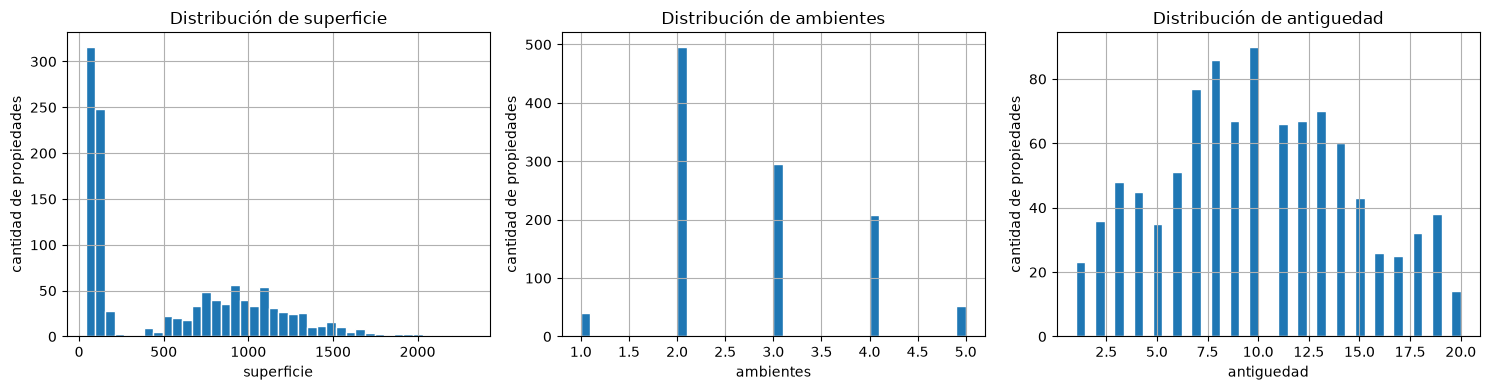

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, numericas):
    props[col].dropna().hist(bins=40, ax=ax, edgecolor="white")
    ax.set_title(f"Distribución de {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("cantidad de propiedades")

plt.tight_layout()
plt.show()

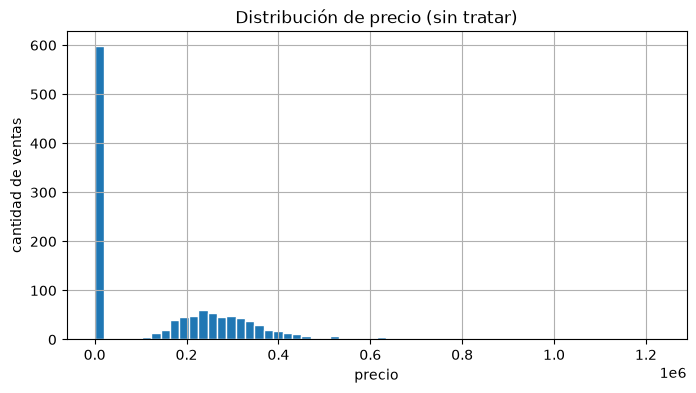

In [10]:
ops["precio"].hist(bins=60, edgecolor="white")
plt.title("Distribución de precio (sin tratar)")
plt.xlabel("precio")
plt.ylabel("cantidad de ventas")
plt.show()

**Qué nos llama la atención:**

- **Superficie:** la mediana general es 431, pero el promedio es más alto y la cola derecha llega hasta 2.314. Ojo: estos valores mezclan dos zonas con unidades distintas (ver sección 3), así que todavía no son interpretables.
- **Ambientes:** los valores van de 1 a 5, y la mayoría de las propiedades tienen 2 o 3.
- **Antigüedad:** los valores se reparten bastante parejo entre 1 y 20 años.
- **Precio:** el histograma es **bimodal**. Hay un grupo de precios muy bajos (cerca de 0 a 1.000) y otro grupo alrededor de 250.000. Esto no parece una distribución normal con una cola larga. Parece que hay dos poblaciones distintas mezcladas.

**Preguntas que nos surgen:**

1. ¿Por qué el precio tiene dos grupos tan separados?
2. ¿Por qué la superficie tiene una cola tan larga hacia valores muy altos?
3. Si hay dos grupos, ¿los demás análisis están mezclando cosas que no son comparables?

Las preguntas 1 y 3 van a aparecer de nuevo más adelante.

In [11]:
# Un primer indicio: ¿las ventas con latitud positiva son las mismas que tienen precio bajo?
ops["grupo_latitud"] = np.where(ops["latitud"] < 0, "latitud negativa", "latitud positiva")
ops.groupby("grupo_latitud")["precio"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
grupo_latitud,,,,,,,,
latitud negativa,587.00,"288,495.40","115,190.60","105,848.70","212,554.60","267,819.40","335,240.60","1,227,231.40"
latitud positiva,598.00,771.80,277.80,301.30,578.10,724.30,907.80,"2,180.20"


Efectivamente: todas las ventas con latitud positiva tienen precios muy bajos, y todas las de latitud negativa tienen precios altos. El próximo paso es entender por qué.

## 3. ¿Cuánto mide un ambiente promedio? (y una anomalía)

Para responder esto hay que unir las dos tablas, ya que la superficie está en `propiedades.csv` y la ubicación en `operaciones.csv`.

In [12]:
df = ops.merge(props, on="id_propiedad", how="inner")

# Las coordenadas indican la zona: latitud negativa → Buenos Aires, positiva → Nueva York
df["zona"] = np.where(df["latitud"] < 0, "Buenos Aires", "Nueva York")

print(df["zona"].value_counts())
print()
df.groupby("zona")["superficie"].describe().round(1)

zona
Nueva York      598
Buenos Aires    587
Name: count, dtype: int64



,count,mean,std,min,25%,50%,75%,max
zona,,,,,,,,
Buenos Aires,587.00,98.10,31.50,40.00,75.00,94.00,116.00,236.00
Nueva York,598.00,"1,015.00",332.90,431.00,775.00,969.00,"1,203.20","2,314.00"


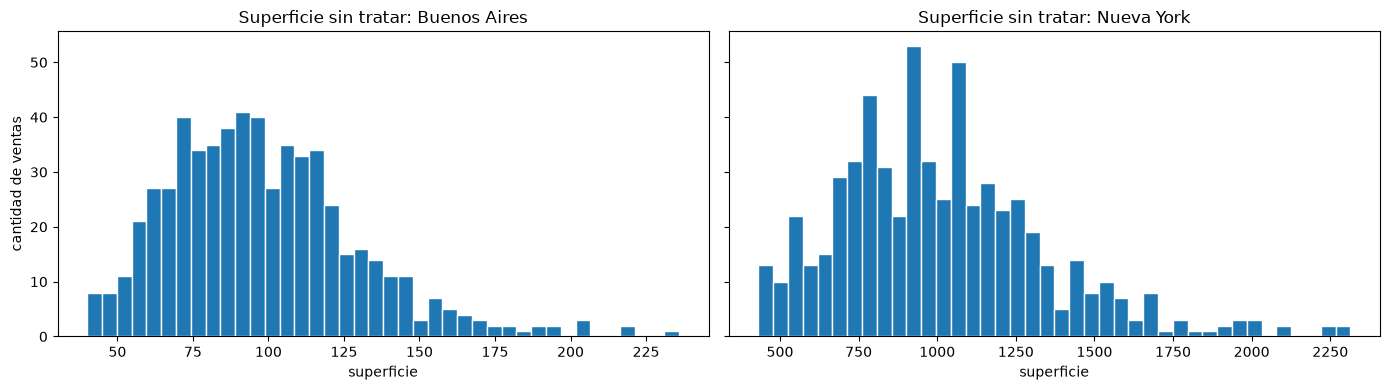

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

for ax, zona in zip(axes, ["Buenos Aires", "Nueva York"]):
    subset = df[df["zona"] == zona]
    ax.hist(subset["superficie"], bins=40, edgecolor="white")
    ax.set_title(f"Superficie sin tratar: {zona}")
    ax.set_xlabel("superficie")

axes[0].set_ylabel("cantidad de ventas")
plt.tight_layout()
plt.show()

**Lo extraño:** si miramos la distribución entera, aparecen **dos mundos**:

- En Buenos Aires la superficie mediana es de **94**, con mínimo 40 y máximo 236.
- En Nueva York la superficie mediana es de **969**, con mínimo 431 y máximo 2.314.

Si tomáramos los números tal cual, diríamos que un ambiente en Nueva York mide unos 360 "metros cuadrados" por ambiente, casi diez veces más que en Buenos Aires. Eso no parece real.

**Hipótesis:** los valores de Nueva York están en **pies cuadrados** y no en metros cuadrados. Un metro cuadrado equivale a aproximadamente 10,76 pies cuadrados, y la diferencia de medianas (969 / 94 ≈ 10,3) es muy cercana a ese factor.

Lo mismo pasa con el precio: los precios de Nueva York rondan los 720, mientras que los de Buenos Aires rondan los 268.000. Esto sugiere que los precios de Nueva York están expresados en **miles de dólares**.

Antes de convertir, dejo esta hipótesis como tal. Más abajo, en la sección 10, la pongo a prueba.

In [14]:
PIE2_A_M2 = 0.092903  # 1 pie cuadrado = 0,092903 m²

es_ny = df["zona"] == "Nueva York"

# Columnas en unidades comparables
df["m2"] = np.where(es_ny, df["superficie"] * PIE2_A_M2, df["superficie"])
df["precio_usd"] = np.where(es_ny, df["precio"] * 1_000, df["precio"])
df["usd_por_m2"] = df["precio_usd"] / df["m2"]

df.groupby("zona")[["m2", "precio_usd", "usd_por_m2"]].median().round(0)

,m2,precio_usd,usd_por_m2
zona,,,
Buenos Aires,94.00,"267,819.00","2,791.00"
Nueva York,90.00,"724,350.00","7,771.00"


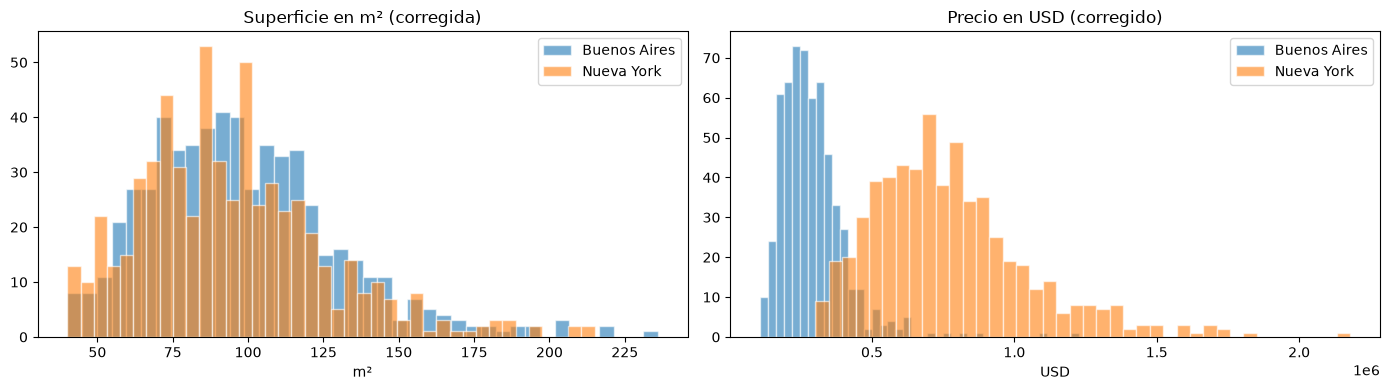

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for zona in ["Buenos Aires", "Nueva York"]:
    subset = df[df["zona"] == zona]
    axes[0].hist(subset["m2"], bins=40, alpha=0.6, label=zona, edgecolor="white")
    axes[1].hist(subset["precio_usd"], bins=40, alpha=0.6, label=zona, edgecolor="white")

axes[0].set_title("Superficie en m² (corregida)")
axes[0].set_xlabel("m²")
axes[1].set_title("Precio en USD (corregido)")
axes[1].set_xlabel("USD")
for ax in axes:
    ax.legend()

plt.tight_layout()
plt.show()

Después de convertir, las distribuciones de superficie de las dos zonas se superponen bastante bien. Esto sostiene la hipótesis. La parte de precio todavía tiene que validarse, y lo hacemos en la sección 10.

**Ahora sí, el tamaño de un ambiente promedio:** calculo los metros cuadrados por ambiente en cada propiedad y luego miro la distribución.

In [16]:
df["m2_por_ambiente"] = df["m2"] / df["ambientes"]

df.groupby("zona")["m2_por_ambiente"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
zona,,,,,,,,
Buenos Aires,530.00,35.40,4.90,25.00,31.70,34.70,38.00,49.00
Nueva York,549.00,35.70,5.20,25.00,31.70,35.00,38.70,49.00


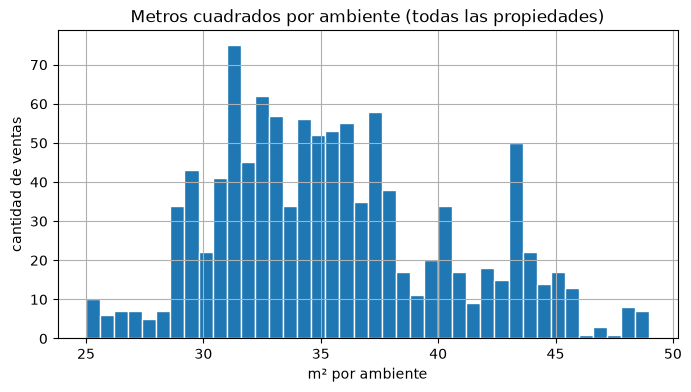

In [17]:
df["m2_por_ambiente"].hist(bins=40, edgecolor="white")
plt.title("Metros cuadrados por ambiente (todas las propiedades)")
plt.xlabel("m² por ambiente")
plt.ylabel("cantidad de ventas")
plt.show()

**Respuesta a la pregunta 3:** un ambiente promedio mide alrededor de **35 m²**. La mediana es de 35, y el rango intercuartil va de unos 32 a 38 m². Esto es consistente en ambas zonas.

Esta cifra se calcula sobre ambientes que incluyen living y dormitorios. Los baños y la cocina suelen no contarse como ambientes, así que el número tiene sentido.

**Lo extraño:** la distribución entera de la superficie no tiene sentido si se toma en su unidad original. Dos ciudades con mediana de 94 y de 969 "metros" cuadrados no pueden compararse de forma directa. La diferencia viene de la unidad, no de la realidad del mercado.

## 4. ¿Las propiedades con pileta son más caras?

Antes de comparar hay que tener en cuenta que la pileta puede estar asociada a otras características, como la superficie o la zona. Por eso miro también los metros cuadrados y el precio por m².

In [18]:
print("Proporción de propiedades con pileta, por zona:")
print(df.groupby("zona")["tiene_pileta"].mean().round(3))
print()

tabla_pileta = df.groupby(["zona", "tiene_pileta"]).agg(
    cantidad=("precio_usd", "count"),
    precio_mediana=("precio_usd", "median"),
    precio_medio=("precio_usd", "mean"),
    m2_mediana=("m2", "median"),
    usd_m2_mediana=("usd_por_m2", "median"),
).round(0)

tabla_pileta

Proporción de propiedades con pileta, por zona:
zona
Buenos Aires   0.16
Nueva York     0.08
Name: tiene_pileta, dtype: float64



cantidad  precio_mediana  precio_medio  m2_mediana  \
zona         tiene_pileta                                                       
Buenos Aires 0                  495      263,303.00    283,195.00       94.00   
             1                   92      308,418.00    317,014.00       93.00   
Nueva York   0                  548      720,700.00    763,130.00       90.00   
             1                   50      836,550.00    866,642.00       92.00   

                           usd_m2_mediana  
zona         tiene_pileta                  
Buenos Aires 0                   2,753.00  
             1                   3,139.00  
Nueva York   0                   7,711.00  
             1                   8,718.00

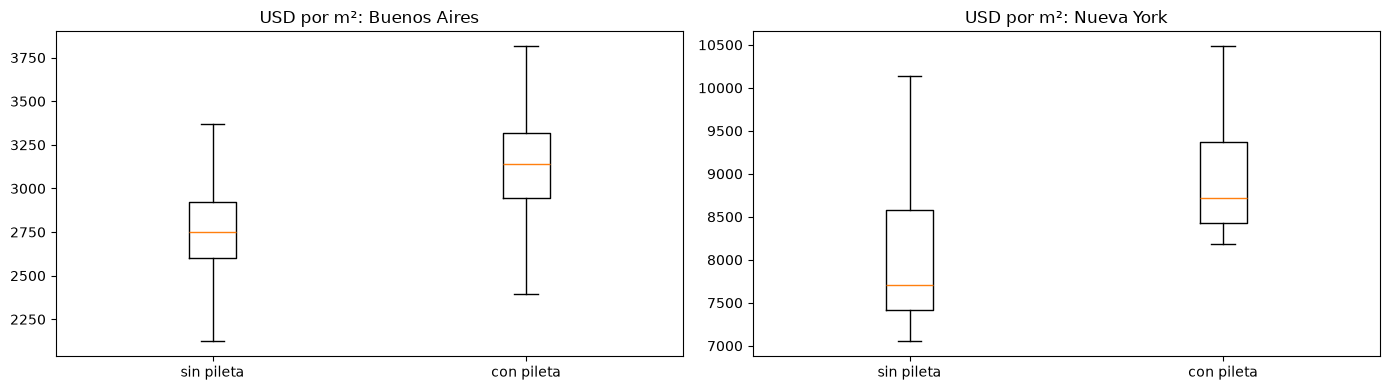

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, zona in zip(axes, ["Buenos Aires", "Nueva York"]):
    subset = df[df["zona"] == zona]
    datos = [subset.loc[subset["tiene_pileta"] == 0, "usd_por_m2"],
             subset.loc[subset["tiene_pileta"] == 1, "usd_por_m2"]]
    ax.boxplot(datos, tick_labels=["sin pileta", "con pileta"], showfliers=False)
    ax.set_title(f"USD por m²: {zona}")

plt.tight_layout()
plt.show()

**Respuesta a la pregunta 4:** sí, en promedio las propiedades con pileta son más caras, pero la diferencia depende de qué se compare.

- En Buenos Aires, la mediana del precio total es de unos 263.000 sin pileta y de 308.000 con pileta.
- En Nueva York, la mediana pasa de unos 721.000 sin pileta a unos 837.000 con pileta.

La superficie mediana es prácticamente la misma en ambos grupos (alrededor de 90 a 94 m²), así que la diferencia no viene del tamaño. En precio por m² la brecha se mantiene: unos 2.750 contra 3.140 USD/m² en Buenos Aires (+14%), y 7.710 contra 8.720 USD/m² en Nueva York (+13%). La pileta parece sumar valor por sí misma, aunque no sabemos cuánto cuesta construirla ni si aparece junto con otras mejoras que no tenemos en el dataset. Vale la pena notar también que solo el 8% de las propiedades de Nueva York tienen pileta, frente al 16% en Buenos Aires.

## 5. ¿Las casas son más caras que los departamentos?

Mismo criterio que en la pregunta anterior: comparar el precio total, pero también el precio por m², para no confundir tamaño con tipo de propiedad.

In [20]:
print("Proporción de casas, por zona:")
print(df.groupby("zona")["es_casa"].mean().round(3))
print()

tabla_casa = df.groupby(["zona", "es_casa"]).agg(
    cantidad=("precio_usd", "count"),
    precio_mediana=("precio_usd", "median"),
    precio_medio=("precio_usd", "mean"),
    m2_mediana=("m2", "median"),
    usd_m2_mediana=("usd_por_m2", "median"),
).round(0)

tabla_casa.rename(index={0: "departamento", 1: "casa"}, level=1)

Proporción de casas, por zona:
zona
Buenos Aires   0.66
Nueva York     0.19
Name: es_casa, dtype: float64



cantidad  precio_mediana  precio_medio  m2_mediana  \
zona         es_casa                                                            
Buenos Aires departamento       202      261,406.00    285,596.00       92.00   
             casa               385      273,617.00    290,017.00       95.00   
Nueva York   departamento       482      700,800.00    740,392.00       90.00   
             casa               116      877,650.00    902,231.00       94.00   

                           usd_m2_mediana  
zona         es_casa                       
Buenos Aires departamento        2,709.00  
             casa                2,824.00  
Nueva York   departamento        7,627.00  
             casa                9,288.00

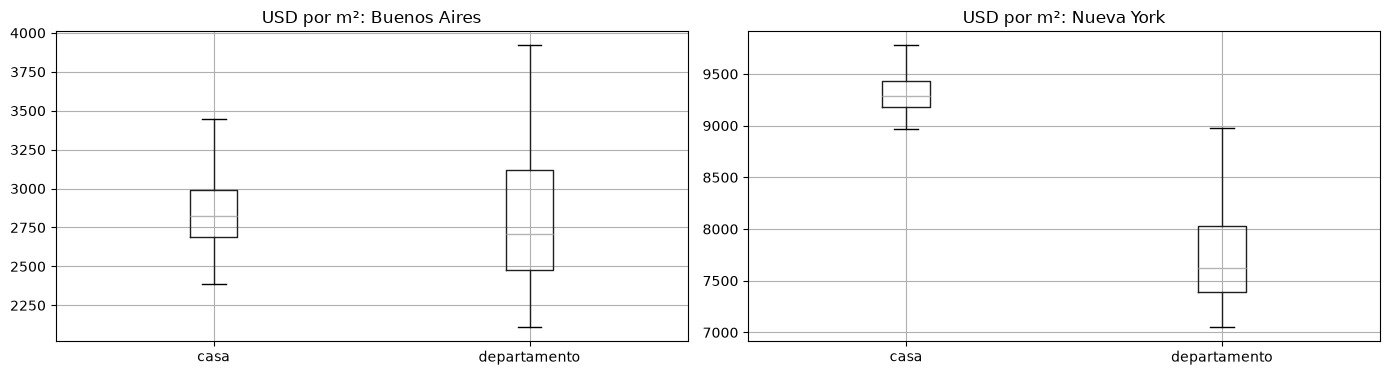

In [21]:
resumen_casa = df.assign(tipo=np.where(df["es_casa"] == 1, "casa", "departamento"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, zona in zip(axes, ["Buenos Aires", "Nueva York"]):
    subset = resumen_casa[resumen_casa["zona"] == zona]
    subset.boxplot(column="usd_por_m2", by="tipo", ax=ax, showfliers=False)
    ax.set_title(f"USD por m²: {zona}")
    ax.set_xlabel("")

plt.suptitle("")
plt.tight_layout()
plt.show()

**Respuesta a la pregunta 5:** en general sí, las casas son más caras, pero la diferencia es muy distinta según la zona.

- En Buenos Aires, la mediana de precio total es de unos 274.000 para casas y 261.000 para departamentos. Por m² la diferencia es chica: 2.824 contra 2.709 USD/m² (+4%).
- En Nueva York, las casas tienen una mediana de unos 878.000 frente a unos 701.000 de los departamentos. Por m² la diferencia es más marcada: 9.288 contra 7.627 USD/m² (+22%).

Conclusión: el tipo de propiedad importa, pero su efecto no es el mismo en las dos ciudades. Además, en Buenos Aires el 66% de las propiedades son casas, así que el promedio general sería muy distinto si se mirara solo una zona. Por eso conviene siempre separar por zona.

## 6. ¿Las propiedades más grandes son más caras?

Acá conviene empezar con un cuidado importante. Si calculamos la correlación entre precio y superficie sin separar por zona, aparece un resultado muy fuerte pero engañoso.

In [22]:
print("Correlación con datos SIN corregir (mezclando zonas y unidades):")
print(df[["precio", "superficie"]].corr().round(2))
print()

print("Correlación con datos CORREGIDOS (sin separar por zona):")
print(df[["precio_usd", "m2"]].corr().round(2))
print()

print("Correlación dentro de cada zona (datos corregidos):")
for zona, grupo in df.groupby("zona"):
    r = grupo[["precio_usd", "m2"]].corr().iloc[0, 1]
    print(f"  {zona}: {r:.2f}")

Correlación con datos SIN corregir (mezclando zonas y unidades):
            precio  superficie
precio        1.00       -0.76
superficie   -0.76        1.00

Correlación con datos CORREGIDOS (sin separar por zona):
            precio_usd   m2
precio_usd        1.00 0.49
m2                0.49 1.00

Correlación dentro de cada zona (datos corregidos):
  Buenos Aires: 0.73
  Nueva York: 0.93


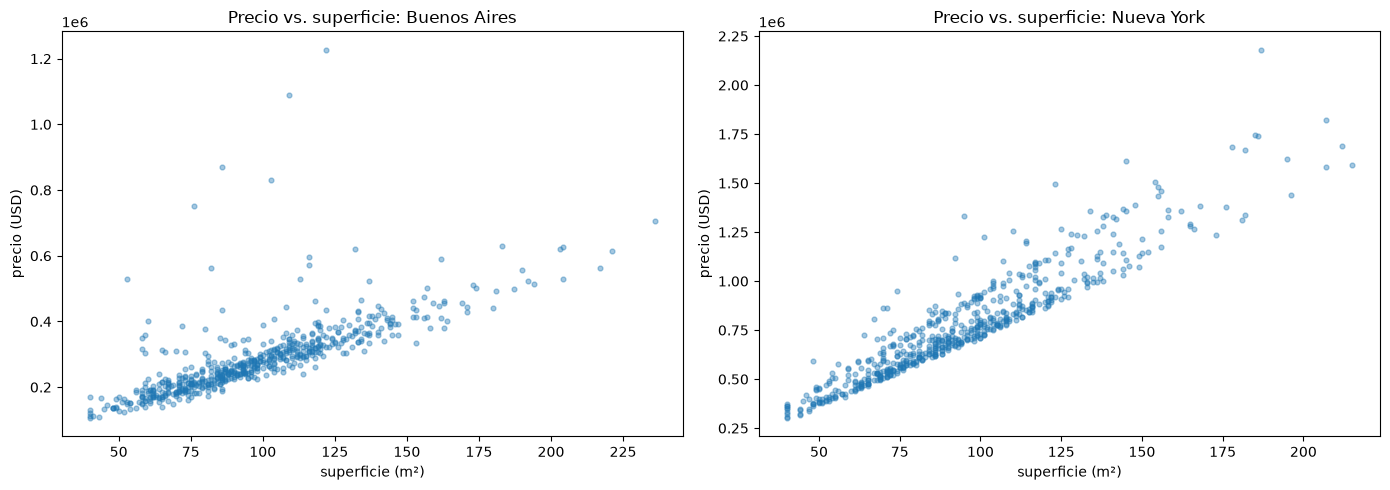

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, zona in zip(axes, ["Buenos Aires", "Nueva York"]):
    subset = df[df["zona"] == zona]
    ax.scatter(subset["m2"], subset["precio_usd"], alpha=0.4, s=12)
    ax.set_title(f"Precio vs. superficie: {zona}")
    ax.set_xlabel("superficie (m²)")
    ax.set_ylabel("precio (USD)")

plt.tight_layout()
plt.show()

**Respuesta a la pregunta 6:** sí. Dentro de cada zona, las propiedades más grandes son más caras, y la relación es fuerte:

- En Buenos Aires la correlación es de alrededor de **0,73**.
- En Nueva York es de alrededor de **0,93**.

La correlación sin separar por zona da un valor de -0,76 con los datos crudos, que es exactamente lo contrario de lo que dicen los datos por zona. Esto ocurre porque en los datos crudos las propiedades de Nueva York tienen más superficie en "pies cuadrados" y precios de "miles", así que la correlación queda explicada por la unidad y no por el mercado. Es un buen ejemplo de por qué hay que revisar los datos antes de calcular cualquier estadística.

## 7. ¿Las propiedades más antiguas son más baratas?

Hay 201 propiedades sin dato de antigüedad. Las excluyo de este análisis.

In [24]:
antiguedad_ok = df.dropna(subset=["antiguedad"]).copy()

print("Correlación entre antigüedad y precio por m²:")
for zona, grupo in antiguedad_ok.groupby("zona"):
    r = grupo[["antiguedad", "usd_por_m2"]].corr().iloc[0, 1]
    print(f"  {zona}: {r:.2f}")
print()

antiguedad_ok["rango_antiguedad"] = pd.cut(
    antiguedad_ok["antiguedad"], bins=[0, 5, 10, 15, 20],
    labels=["1-5", "6-10", "11-15", "16-20"], include_lowest=True
)

antiguedad_ok.groupby(["zona", "rango_antiguedad"], observed=True)["usd_por_m2"].agg(
    ["count", "median"]
).round(0)

Correlación entre antigüedad y precio por m²:
  Buenos Aires: -0.20
  Nueva York: 0.17



count   median
zona         rango_antiguedad                
Buenos Aires 1-5                  41 3,129.00
             6-10                185 2,876.00
             11-15               155 2,756.00
             16-20                98 2,680.00
Nueva York   1-5                 144 7,906.00
             6-10                182 7,561.00
             11-15               147 7,460.00
             16-20                33 9,166.00

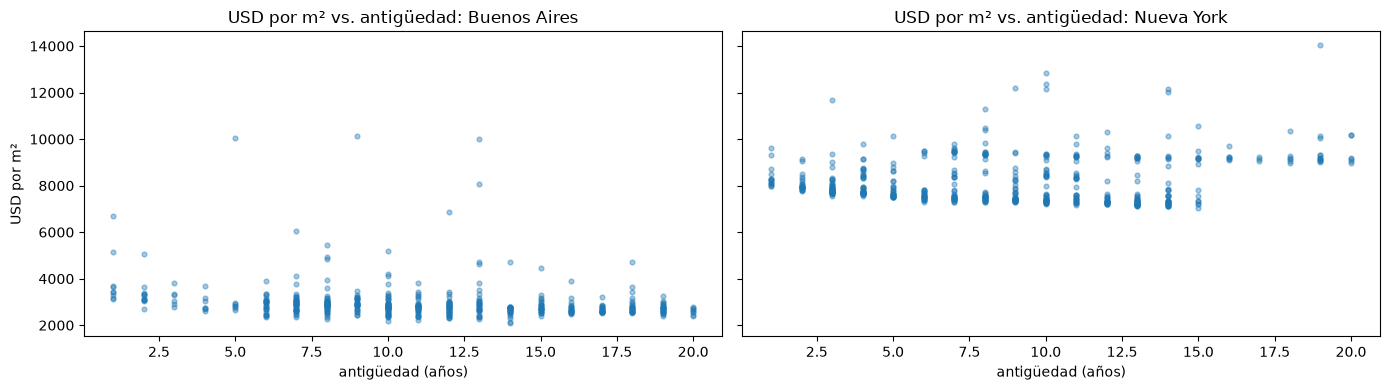

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

for ax, zona in zip(axes, ["Buenos Aires", "Nueva York"]):
    subset = antiguedad_ok[antiguedad_ok["zona"] == zona]
    ax.scatter(subset["antiguedad"], subset["usd_por_m2"], alpha=0.4, s=12)
    ax.set_title(f"USD por m² vs. antigüedad: {zona}")
    ax.set_xlabel("antigüedad (años)")

axes[0].set_ylabel("USD por m²")
plt.tight_layout()
plt.show()

**Respuesta a la pregunta 7:** no hay una relación fuerte.

- En Buenos Aires hay una tendencia moderada: las propiedades de 1 a 5 años tienen una mediana de unos 3.130 USD/m², y las de 16 a 20 años unos 2.680. La correlación es de -0,20, así que las más nuevas tienden a ser un poco más caras por m².
- En Nueva York no se cumple. La correlación es de +0,17, es decir, las más viejas tienden a ser algo más caras por m² (unos 9.170 USD/m² en el grupo de 16 a 20 años contra 7.910 en el de 1 a 5).

Entonces, la respuesta es: **en Buenos Aires, un poco sí; en Nueva York, no, e incluso se da al revés**. Como las dos correlaciones son moderadas o débiles y van en sentidos opuestos, la antigüedad no parece un factor decisivo. Una posible explicación es que en Nueva York las propiedades antiguas están en zonas más caras (como edificios históricos en barrios céntricos), pero no tenemos el barrio para verificarlo.

## 8. ¿Qué relación tiene la ubicación con el precio?

Las coordenadas están concentradas en dos zonas bastante chicas (Buenos Aires y Nueva York). Dentro de cada una, la pregunta es si las propiedades más cercanas al centro son más caras por m².

Para eso calculo la distancia a un punto de referencia en cada ciudad (aproximadamente el Obelisco y Times Square). Es una aproximación simple, pero suficiente para ver la tendencia.

In [26]:
def distancia_km(lat, lon, lat_ref, lon_ref):
    # Aproximación plana: 1 grado de latitud ≈ 111 km; la longitud se corrige por coseno
    dy = (lat - lat_ref) * 111
    dx = (lon - lon_ref) * 111 * np.cos(np.radians(lat_ref))
    return np.sqrt(dx**2 + dy**2)

CENTRO = {
    "Buenos Aires": (-34.6037, -58.3816),   # Obelisco
    "Nueva York": (40.7580, -73.9855),      # Times Square
}

df["distancia_centro_km"] = np.nan
for zona, (lat_ref, lon_ref) in CENTRO.items():
    mascara = df["zona"] == zona
    df.loc[mascara, "distancia_centro_km"] = distancia_km(
        df.loc[mascara, "latitud"], df.loc[mascara, "longitud"], lat_ref, lon_ref
    )

for zona, grupo in df.groupby("zona"):
    r = grupo[["distancia_centro_km", "usd_por_m2"]].corr().iloc[0, 1]
    print(f"Correlación distancia vs. USD por m² en {zona}: {r:.2f}")

Correlación distancia vs. USD por m² en Buenos Aires: -0.43
Correlación distancia vs. USD por m² en Nueva York: -0.01


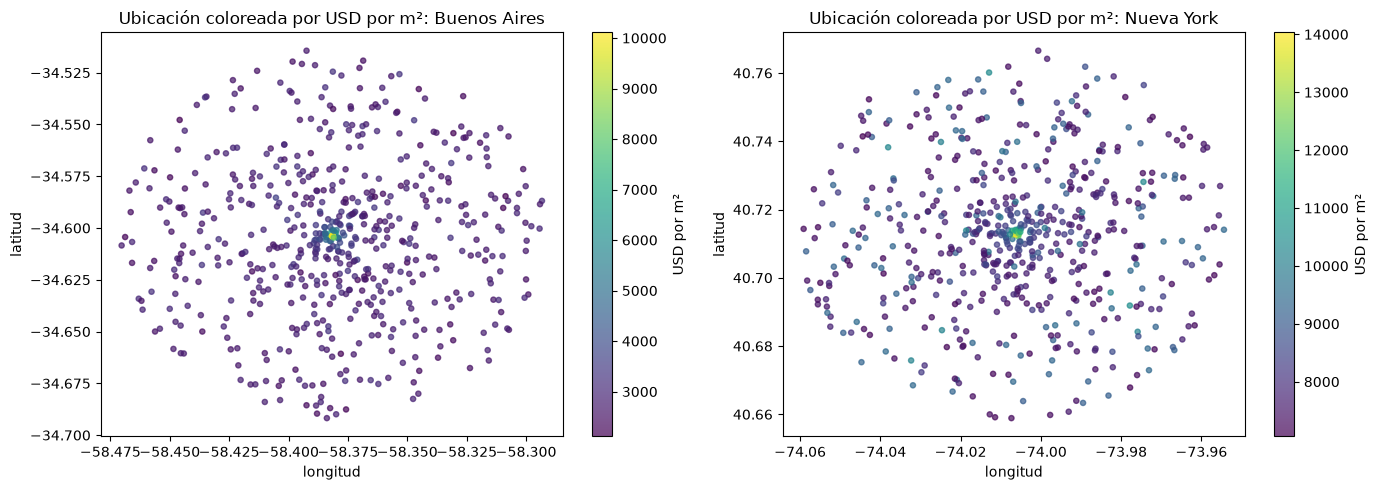

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, zona in zip(axes, ["Buenos Aires", "Nueva York"]):
    subset = df[df["zona"] == zona]
    sc = ax.scatter(subset["longitud"], subset["latitud"],
                    c=subset["usd_por_m2"], cmap="viridis", s=14, alpha=0.7)
    ax.set_title(f"Ubicación coloreada por USD por m²: {zona}")
    ax.set_xlabel("longitud")
    ax.set_ylabel("latitud")
    plt.colorbar(sc, ax=ax, label="USD por m²")

plt.tight_layout()
plt.show()

In [28]:
df["cuartil_distancia"] = pd.Series(index=df.index, dtype="object")
for zona in CENTRO:
    mascara = df["zona"] == zona
    df.loc[mascara, "cuartil_distancia"] = pd.qcut(
        df.loc[mascara, "distancia_centro_km"], 4, labels=["1 (más cerca)", "2", "3", "4 (más lejos)"]
    )

df.groupby(["zona", "cuartil_distancia"], observed=True)["usd_por_m2"].median().round(0).unstack(0)

zona,Buenos Aires,Nueva York
cuartil_distancia,,
1 (más cerca),"3,155.00","7,634.00"
2,"2,795.00","8,296.00"
3,"2,757.00","7,812.00"
4 (más lejos),"2,689.00","7,666.00"


**Respuesta a la pregunta 8:** depende de la ciudad.

- En Buenos Aires hay una relación negativa moderada: cuanto más lejos del centro, menor precio por m². La correlación es de -0,43 y la mediana baja de unos 3.150 USD/m² en el primer cuartil a unos 2.690 en el último.
- En Nueva York prácticamente no hay relación con la distancia al centro (correlación cercana a cero). Esto puede deberse a que el área es chica, a que el punto de referencia no captura bien la estructura de precios de Manhattan, o a que hay otros factores (vista, edificio, piso) que no tenemos.

Una limitación importante: el dataset solo tiene latitud y longitud, sin barrio. Un análisis con barrios sería más preciso.

## 9. ¿La fecha de venta influye en el precio?

Las ventas van desde 2021 hasta fines de 2025. Veo si el precio por m² cambia con el año y si hay una tendencia.

In [29]:
df["fecha"] = pd.to_datetime(df["fecha"])
df["anio"] = df["fecha"].dt.year

print("Rango de fechas:", df["fecha"].min().date(), "a", df["fecha"].max().date())
print()

tabla_anio = df.groupby(["anio", "zona"])["usd_por_m2"].median().round(0).unstack("zona")
tabla_anio

Rango de fechas: 2021-01-01 a 2025-12-29



zona,Buenos Aires,Nueva York
anio,,
2021,"2,843.00","7,845.00"
2022,"2,760.00","7,754.00"
2023,"2,771.00","7,820.00"
2024,"2,790.00","7,709.00"
2025,"2,812.00","7,778.00"


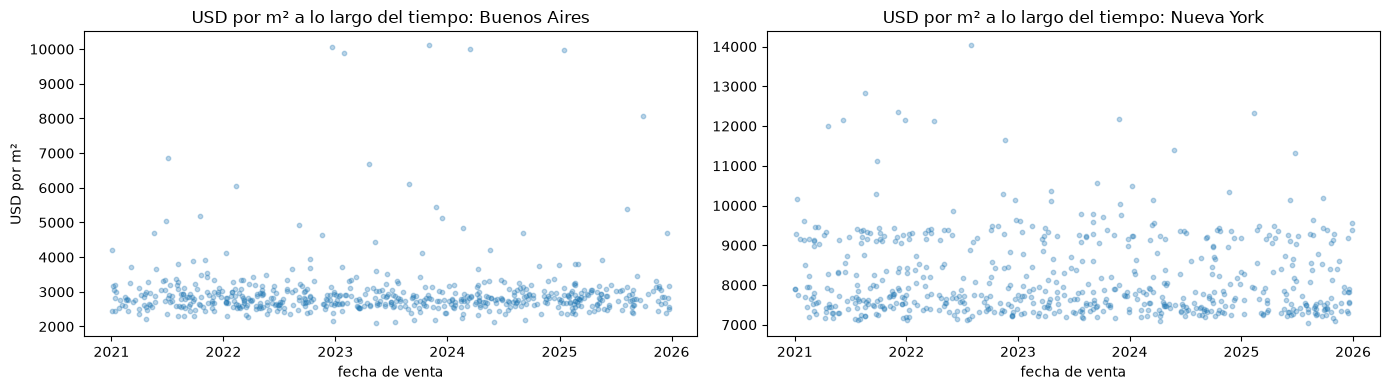

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, zona in zip(axes, ["Buenos Aires", "Nueva York"]):
    subset = df[df["zona"] == zona]
    ax.scatter(subset["fecha"], subset["usd_por_m2"], alpha=0.3, s=10)
    ax.set_title(f"USD por m² a lo largo del tiempo: {zona}")
    ax.set_xlabel("fecha de venta")

axes[0].set_ylabel("USD por m²")
plt.tight_layout()
plt.show()

In [ ]:
for zona, grupo in df.groupby("zona"):
    dias = grupo["fecha"].map(pd.Timestamp.toordinal)
    r = np.corrcoef(dias, grupo["usd_por_m2"])[0, 1]
    print(f"Correlación fecha vs. USD por m² en {zona}: {r:.2f}")

**Respuesta a la pregunta 9:** no, al menos no de forma visible en estos datos.

- La mediana de precio por m² se mantiene bastante estable año a año, en torno a 2.800 USD/m² en Buenos Aires y a 7.800 USD/m² en Nueva York.
- La correlación entre fecha y precio por m² es prácticamente cero en ambas zonas (0,01 en Buenos Aires y -0,07 en Nueva York).

Hay que tener cuidado: el dataset no tiene inflación ni tipo de cambio, y los precios de Buenos Aires podrían estar en pesos o en dólares de distintas épocas. Si el precio estuviera en pesos, la estabilidad sería sospechosa. Como no sabemos la moneda de origen, la conclusión está condicionada a eso.

## 10. Investigación de la anomalía: de dónde sale

Me llamó la atención la diferencia entre zonas en superficie y precio. Antes de corregir los datos hay que poner a prueba la hipótesis, porque corregir sin verificar es una forma de inventar datos.

Tres chequeos:

1. ¿Las coordenadas son correctas?
2. ¿Las distribuciones se parecen después de convertir?
3. ¿Cuánto cambian las conclusiones si no corregimos?

In [31]:
# 1. Coordenadas: ¿caen en las ciudades que suponemos?
print("Rango de coordenadas por zona:")
print(df.groupby("zona")[["latitud", "longitud"]].agg(["min", "max"]).round(3))
print()
print("Buenos Aires ≈ lat -34,6 / lon -58,4")
print("Nueva York ≈ lat 40,7 / lon -74,0")
print("→ Las coordenadas corresponden a cada ciudad. La latitud positiva es correcta: Nueva York está al norte del ecuador.")

Rango de coordenadas por zona:
             latitud        longitud       
                 min    max      min    max
zona                                       
Buenos Aires  -34.69 -34.51   -58.47 -58.29
Nueva York     40.66  40.77   -74.06 -73.95

Buenos Aires ≈ lat -34,6 / lon -58,4
Nueva York ≈ lat 40,7 / lon -74,0
→ Las coordenadas corresponden a cada ciudad. La latitud positiva es correcta: Nueva York está al norte del ecuador.


In [32]:
# 2. Distribuciones: ¿coinciden los cuantiles después de convertir?
cuantiles = [0.0, 0.25, 0.5, 0.75, 1.0]

comparacion = pd.DataFrame({
    "BsAs, superficie original (m²)": df.loc[df["zona"] == "Buenos Aires", "superficie"].quantile(cuantiles).values,
    "NY, superficie original (pies²)": df.loc[df["zona"] == "Nueva York", "superficie"].quantile(cuantiles).values,
    "NY, superficie convertida (m²)": df.loc[df["zona"] == "Nueva York", "m2"].quantile(cuantiles).values,
}, index=["mínimo", "Q1", "mediana", "Q3", "máximo"]).round(1)

comparacion

,"BsAs, superficie original (m²)","NY, superficie original (pies²)","NY, superficie convertida (m²)"
mínimo,40.00,431.00,40.00
Q1,75.00,775.00,72.00
mediana,94.00,969.00,90.00
Q3,116.00,"1,203.20",111.80
máximo,236.00,"2,314.00",215.00


In [33]:
# Razón entre medianas antes de convertir vs. el factor teórico
mediana_bs = df.loc[df["zona"] == "Buenos Aires", "superficie"].median()
mediana_ny = df.loc[df["zona"] == "Nueva York", "superficie"].median()

print(f"Razón de medianas (NY / BsAs): {mediana_ny / mediana_bs:.2f}")
print(f"Factor pies² por m²:           {1 / PIE2_A_M2:.2f}")
print()
print("Si los valores de NY estuvieran en pies², la razón debería ser cercana a 10,76 si la realidad fuera igual en ambas ciudades.")
print("Además, la mediana corregida de Nueva York (90 m²) es muy parecida a la de Buenos Aires (94 m²), lo que es consistente con que las propiedades sean de tamaño similar y solo cambie la unidad.")

Razón de medianas (NY / BsAs): 10.31
Factor pies² por m²:           10.76

Si los valores de NY estuvieran en pies², la razón debería ser cercana a 10,76 si la realidad fuera igual en ambas ciudades.
Además, la mediana corregida de Nueva York (90 m²) es muy parecida a la de Buenos Aires (94 m²), lo que es consistente con que las propiedades sean de tamaño similar y solo cambie la unidad.


In [34]:
# 3. ¿Qué pasa si no corregimos? Comparamos la correlación precio–superficie
sin_corregir = df[["precio", "superficie"]].corr().iloc[0, 1]
corregido_por_zona = df.groupby("zona").apply(
    lambda g: g[["precio_usd", "m2"]].corr().iloc[0, 1], include_groups=False
)

print(f"Correlación precio–superficie sin corregir (todo junto): {sin_corregir:.2f}")
print("Correlación precio–superficie corregida, por zona:")
print(corregido_por_zona.round(2))

Correlación precio–superficie sin corregir (todo junto): -0.76
Correlación precio–superficie corregida, por zona:
zona
Buenos Aires   0.73
Nueva York     0.93
dtype: float64


**Conclusión de la investigación:**

1. **Las coordenadas están bien.** Caen en Buenos Aires y en Nueva York. Lo que está mal (o más bien, en otra unidad) son las columnas de superficie y precio para las ventas de Nueva York.
2. **Las distribuciones coinciden después de convertir.** Por ejemplo, el mínimo de Nueva York en pies² es 431, que equivale a 40 m². El mínimo de Buenos Aires en m² también es 40. Los cuantiles son muy parecidos, lo que descarta que sean diferencias reales del mercado.
3. **El efecto en las conclusiones es grande.** Sin corregir, la correlación entre precio y superficie da -0,76, un resultado absurdo para el mercado inmobiliario. Corregido y separado por zona, la relación es positiva y fuerte.

**Qué no podemos verificar con estos datos:** que el precio de Nueva York esté en miles de dólares. Es la interpretación más razonable porque el precio por m² resultante (unos 7.800 USD/m²) es verosímil para una ciudad como Nueva York, pero la confirmación tendría que venir del portal que compartió los datos. Lo dejamos como supuesto explícito.

**Por qué esto importa más allá de este trabajo:** un análisis que no revisa las unidades de origen puede llegar a conclusiones completamente equivocadas, como una correlación negativa entre superficie y precio o un ambiente de 350 m². Antes de calcular cualquier estadística hay que entender qué representa cada columna.

## 11. Conclusiones

| # | Pregunta | Respuesta corta |
|---|---|---|
| 1 | Descripción de los datos | 1.200 propiedades, 1.185 vendidas (15 sin venta). Una fila por propiedad en uno y una fila por venta en el otro. |
| 2 | Exploración inicial | Precio bimodal y superficie con cola larga. La bimodalidad es la primera señal de que las zonas no son comparables. |
| 3 | Tamaño de un ambiente | Alrededor de 35 m² por ambiente. Lo extraño es que la superficie de Nueva York estaba en pies², lo que generaba dos mundos. |
| 4 | Pileta | Sí. Con superficies similares, las que tienen pileta cuestan unos 13-14% más por m². |
| 5 | Casas vs. departamentos | Sí en Nueva York (unos 22% más por m²). En Buenos Aires la diferencia es chica (unos 4%). |
| 6 | Superficie | Sí, la relación es fuerte dentro de cada zona (0,73 en BsAs, 0,93 en NY). |
| 7 | Antigüedad | Poco. En Buenos Aires las más nuevas son algo más caras por m² (-0,20). En Nueva York no se observa, e incluso aparece lo contrario (+0,17). |
| 8 | Ubicación | En Buenos Aires, cuanto más lejos del centro, menor precio por m². En Nueva York no se observa. |
| 9 | Fecha de venta | No se observa una influencia clara en el precio por m². |
| 10 | Investigación | La anomalía de unidades en Nueva York. Lo verificamos con cuantiles, coordenadas y el efecto en las correlaciones. |

**Aprendizaje principal:** antes de responder preguntas sobre qué determina el precio, hay que asegurarse de que los datos sean comparables. La mayoría de los resultados "raros" que aparecen en el análisis inicial venían de mezclar unidades, no de comportamientos reales del mercado.